# Лабораторная работа 5-6: Сравнительный анализ методов кластеризации 

#### __1. Загрузка данных и подготовка__

Загрузим подготовленный датасет из 3 лабораторной работы.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.manifold import TSNE
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Настройка стилей графиков
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("Set2")
plt.rcParams['figure.figsize'] = (12, 8)

# Настройка отображения
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Загрузка данных
df = pd.read_csv('Data\Dataset_3laba.csv', sep = ',', encoding='latin1')

features = ['memory_variability', 'max_cpus', 'max_memory', 'page_cache_memory', 'cycles_per_instruction_norm']

X = df[features].copy().dropna()

# Масштабирование
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA для визуализации
pca = PCA(n_components=5)
X_pca = pca.fit_transform(X_scaled)

print(f"Размер данных: {X_scaled.shape}")
print(f"Доля объясненной дисперсии PCA: {pca.explained_variance_ratio_.sum():.2%}")

print("\nПервые 5 строк:")
df.head()


Размер данных: (498, 5)
Доля объясненной дисперсии PCA: 100.00%

Первые 5 строк:


,duration,instance_index,memory_variability,avg_cpus,avg_memory,max_cpus,max_memory,page_cache_memory,cycles_per_instruction_norm,memory_accesses_per_instruction_std
0,0.3,111,2.045086,0.008392,0.009476,0.047913,0.019379,0.003220,0.063542,-0.788944
1,0.3,111,1.012154,0.027100,0.027618,0.073608,0.027954,0.001808,0.063542,-0.788944
2,0.3,111,1.547122,0.024933,0.012466,0.117676,0.019287,0.002392,0.087088,-0.245127
3,0.3,111,1.763230,0.019135,0.010956,0.120972,0.019318,0.001934,0.095564,-0.217250
4,0.3,111,2.039740,0.001163,0.000959,0.011063,0.001957,0.000813,0.063542,-0.788944


#### __1. Иерархическая кластеризация__
Построение дендрограмм для всех комбинаций

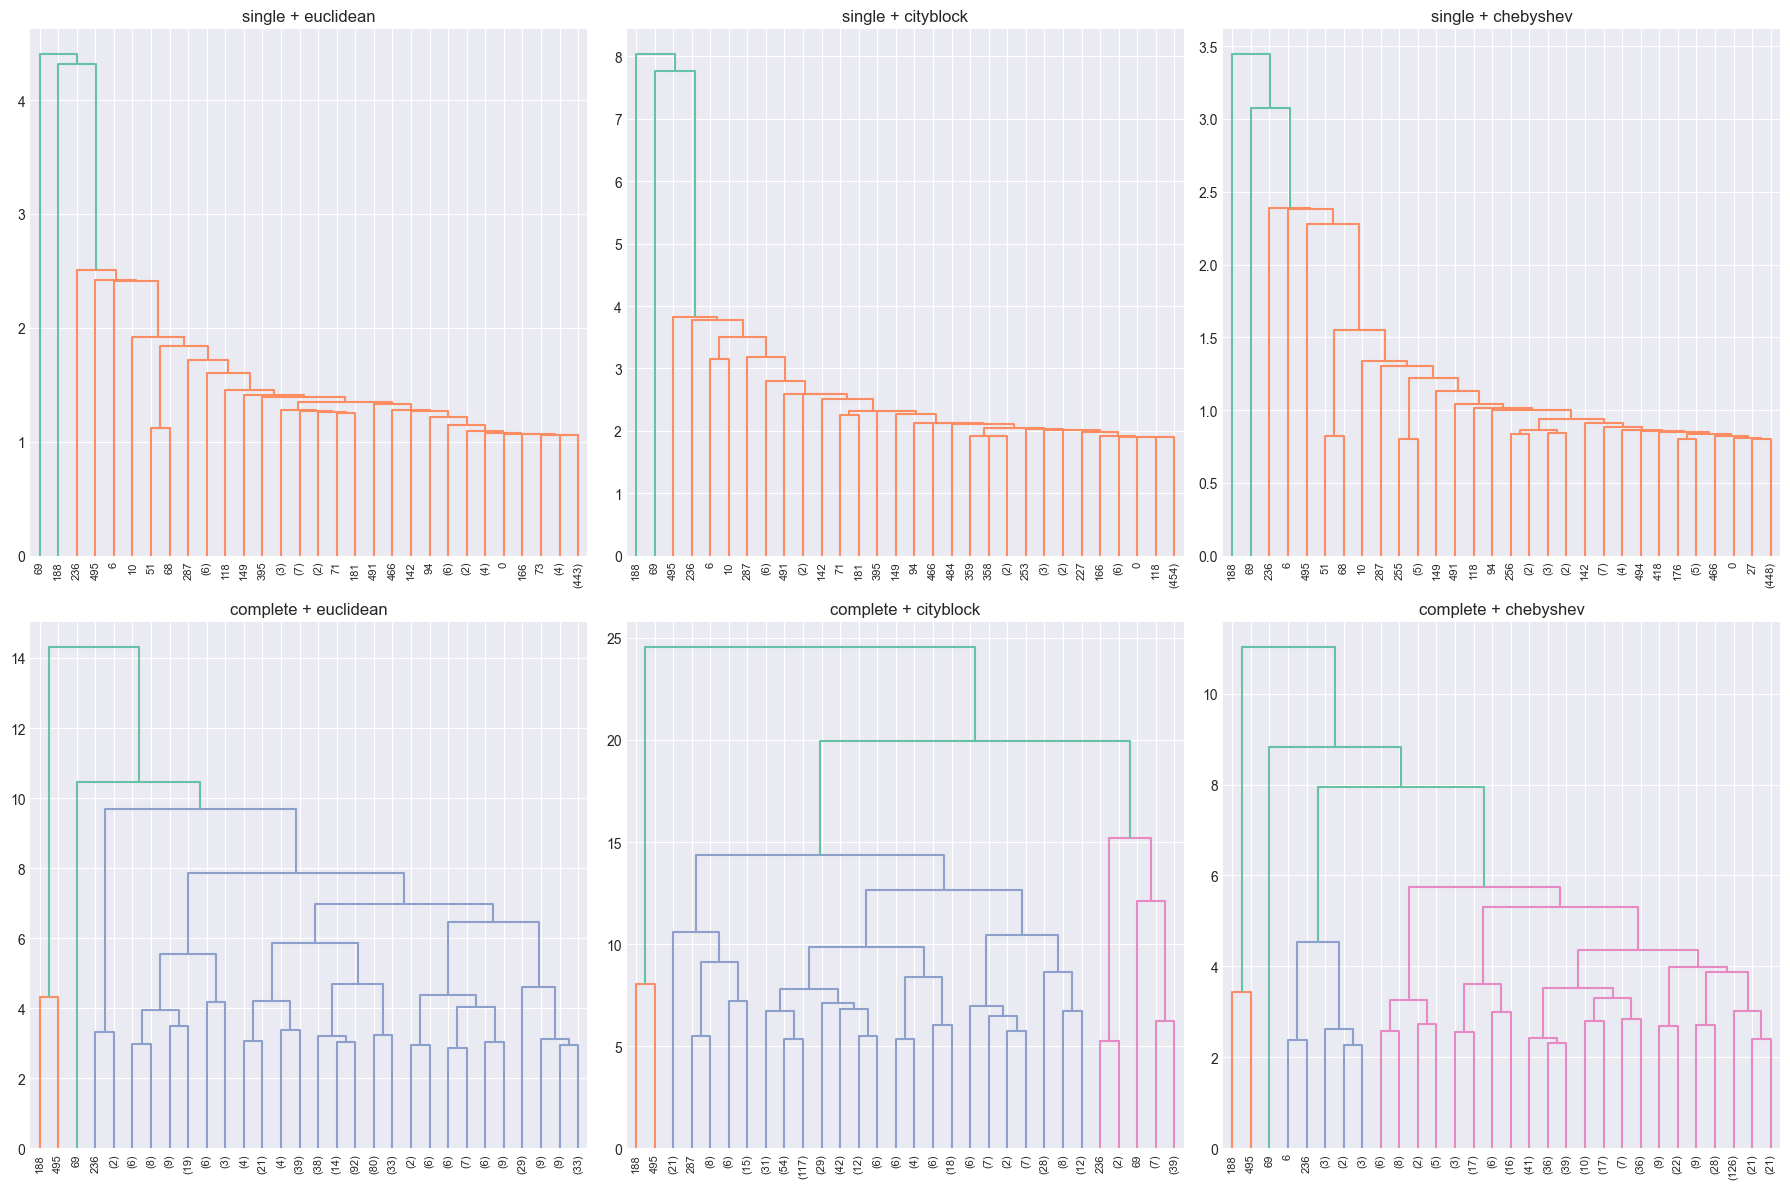

In [2]:
# Параметры для анализа
linkage_methods = ['single', 'complete']            # одиночная связь (single), полная связь (complete)
metrics = ['euclidean', 'cityblock', 'chebyshev']   # Евклидова (euclidean), Манхэттенская (cityblock), Чебышева (chebyshev)

manual_k = {
    'single_euclidean': 2,      #   2
    'single_cityblock': 2,      #   2
    'single_chebyshev': 2,      #   2
    'complete_euclidean': 6,    #   3
    'complete_cityblock': 3,    #   3
    'complete_chebyshev': 6,    #   2
}

USE_MANUAL_K = True

results_hierarchical = {}

for linkage_method in linkage_methods:
    for metric in metrics:
        Z = linkage(X_scaled, method=linkage_method, metric=metric)

        key = f"{linkage_method}_{metric}"

        if USE_MANUAL_K:
            k = manual_k[key]
            model = AgglomerativeClustering(n_clusters=k, linkage=linkage_method, metric=metric)
            labels = model.fit_predict(X_scaled)
            if len(set(labels)) > 1:
                score = silhouette_score(X_scaled, labels, metric=metric)
            else:
                score = -1

            results_hierarchical[key] = {
                'best_k': k,
                'silhouette': score
            }

        else:
            best_score = -1
            best_k = 2
            for k in range(2, 8):
                model = AgglomerativeClustering(n_clusters=k, linkage=linkage_method, metric=metric)
                labels = model.fit_predict(X_scaled)
                if len(set(labels)) > 1:
                    score = silhouette_score(X_scaled, labels, metric=metric)
                    print(f"  k={k}: Silhouette = {score:.4f}")
                    if score > best_score:
                        best_score = score
                        best_k = k

            results_hierarchical[key] = {
                'best_k': best_k,
                'silhouette': best_score
            }
            print(f"\nРекомендуемое k: {best_k} (silhouette = {best_score:.4f})")
# Создание подграфиков 2x3
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

plot_idx = 0

for linkage_method in linkage_methods:
    for metric in metrics:
        # Построение матрицы связей и дендрограммы
        Z = linkage(X_scaled, method=linkage_method, metric=metric)
        dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90,
                   leaf_font_size=8, ax=axes[plot_idx])
        axes[plot_idx].set_title(f'{linkage_method} + {metric}')
        plot_idx += 1

plt.tight_layout()
plt.show()

Выполнение разбиения на оптимальное k и визуализация


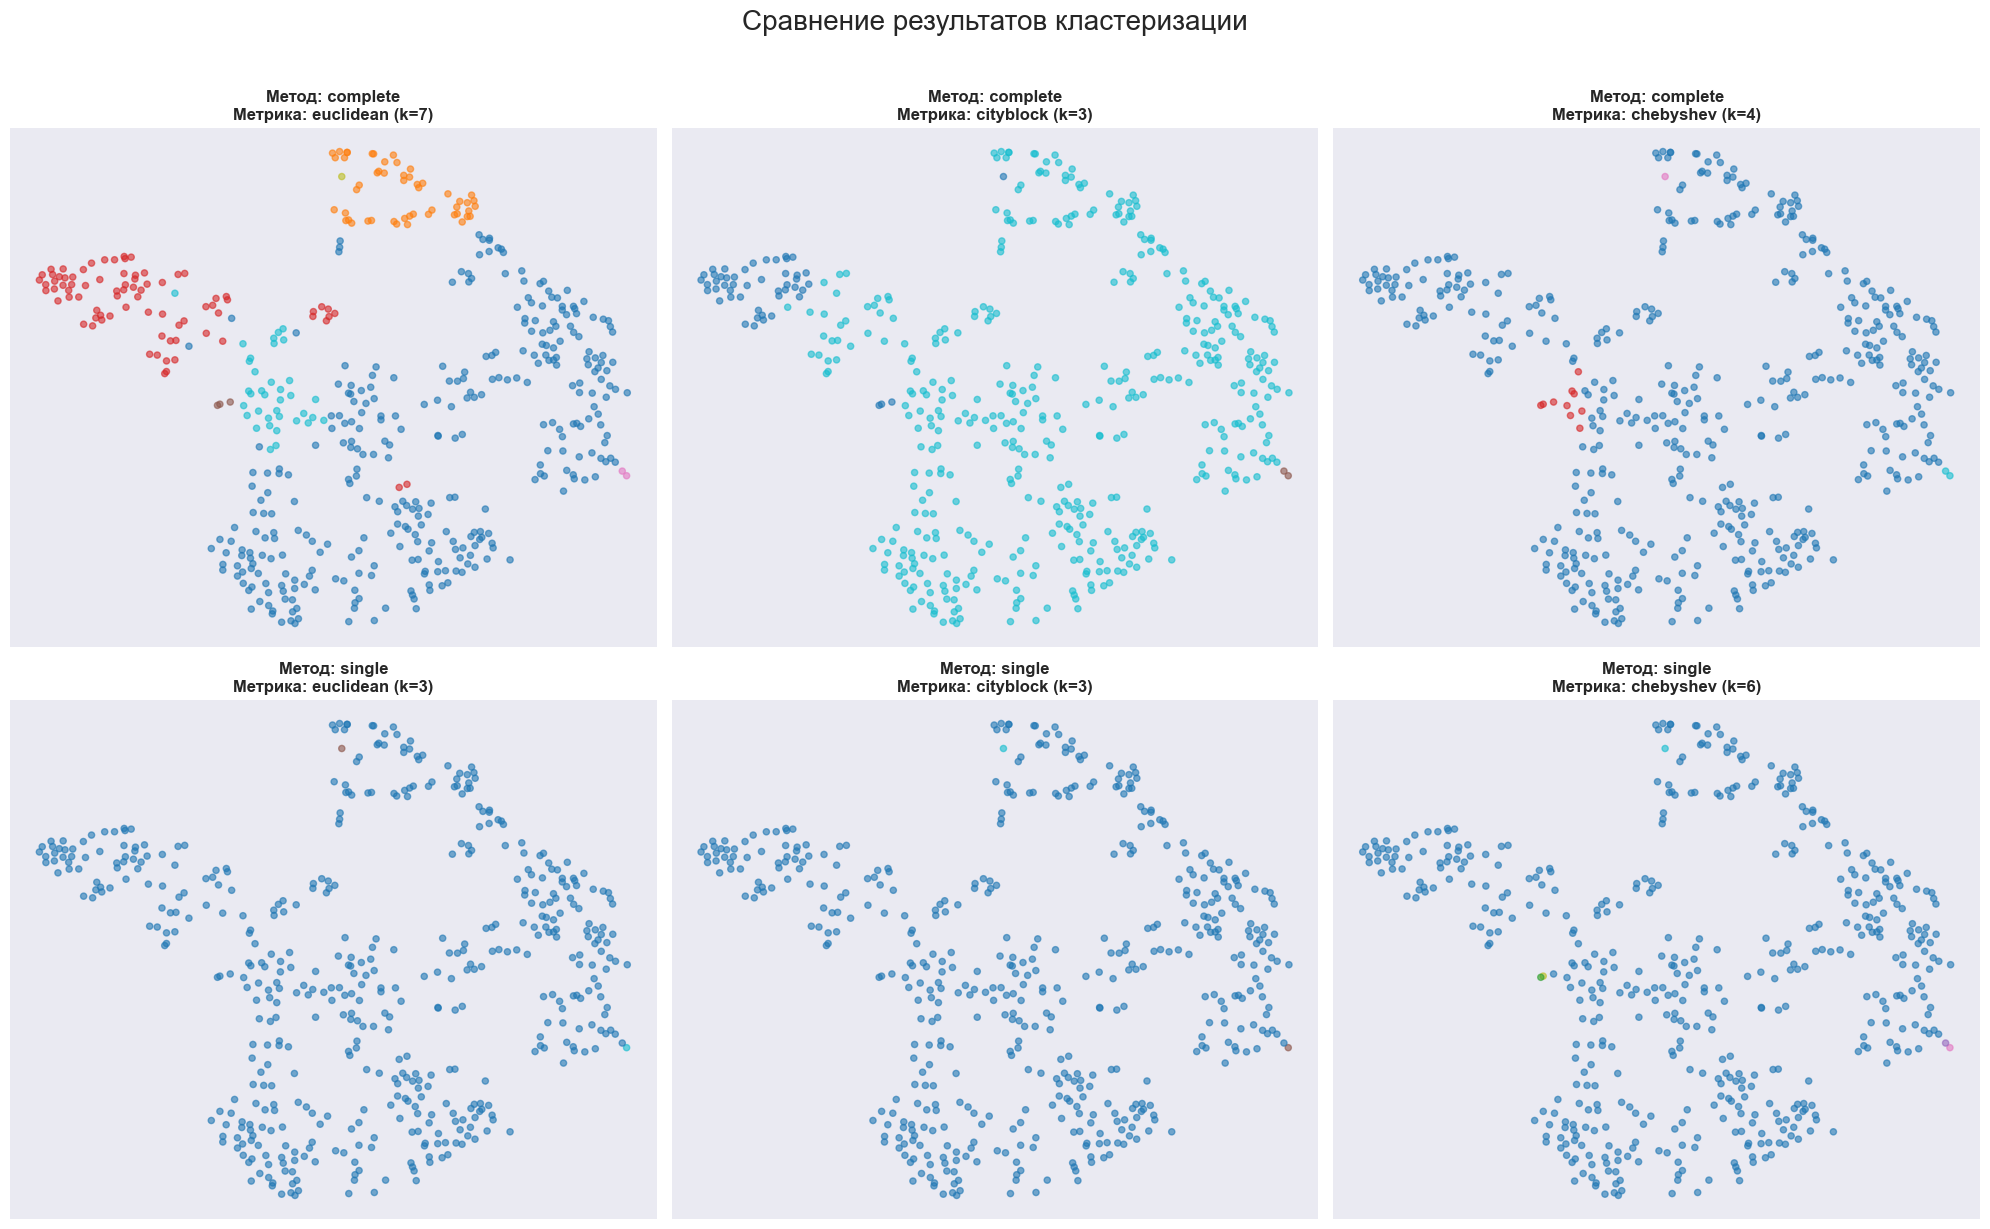

In [3]:
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from sklearn.manifold import TSNE

manual_k = {
    'single_euclidean': 3,
    'single_cityblock': 3,
    'single_chebyshev': 6,
    'complete_euclidean': 7,
    'complete_cityblock': 3,
    'complete_chebyshev': 4
}


tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)


fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()


sorted_configs = sorted(manual_k.keys(), key=lambda x: x.startswith('complete'), reverse=True)

for i, config in enumerate(sorted_configs):
    method, metric = config.split('_')
    k = manual_k[config]

    # Обучаем модель
    model = AgglomerativeClustering(n_clusters=k, linkage=method, metric=metric)
    labels = model.fit_predict(X_scaled)

    # Отрисовка
    ax = axes[i]
    scatter = ax.scatter(X_tsne[:, 0], X_tsne[:, 1],
                         c=labels,
                         cmap='tab10',
                         s=20,
                         alpha=0.6)

    ax.set_title(f"Метод: {method}\nМетрика: {metric} (k={k})", fontsize=12, fontweight='bold')
    ax.set_xticks([])
    ax.set_yticks([])


plt.suptitle("Сравнение результатов кластеризации", fontsize=20, y=1.02)
plt.tight_layout()
plt.show()


Расчет коэффициента силуэта для каждого разбиения (сводная таблица)

In [4]:
print("\n" + "="*70)
print("Сводная таблица результатов иерархической кластеризации")
print("="*70)
print(f"{'Метод связи':<12} {'Метрика':<12} {'Оптимальное k':<15} {'Silhouette':<12}")
print("-"*70)

for config, data in results_hierarchical.items():
    method, metric = config.split('_')
    print(f"{method:<12} {metric:<12} {data['best_k']:<15} {data['silhouette']:.4f}")


Сводная таблица результатов иерархической кластеризации
Метод связи  Метрика      Оптимальное k   Silhouette  
----------------------------------------------------------------------
single       euclidean    2               0.6642
single       cityblock    2               0.6257
single       chebyshev    2               0.7625
complete     euclidean    6               0.3053
complete     cityblock    3               0.3916
complete     chebyshev    6               0.1527


#### __2. Алгоритм k-средних (k-means)__

Метрики расстояния: Евклидова (используется по умолчанию), Манхэттенская (для сравнения). Используя метод локтя (Elbow method), определим оптимальное количество 
кластеров `k`.


k-means с метрикой: euclidean
Оптимальное k: 2

k-means с метрикой: cityblock
Оптимальное k: 2


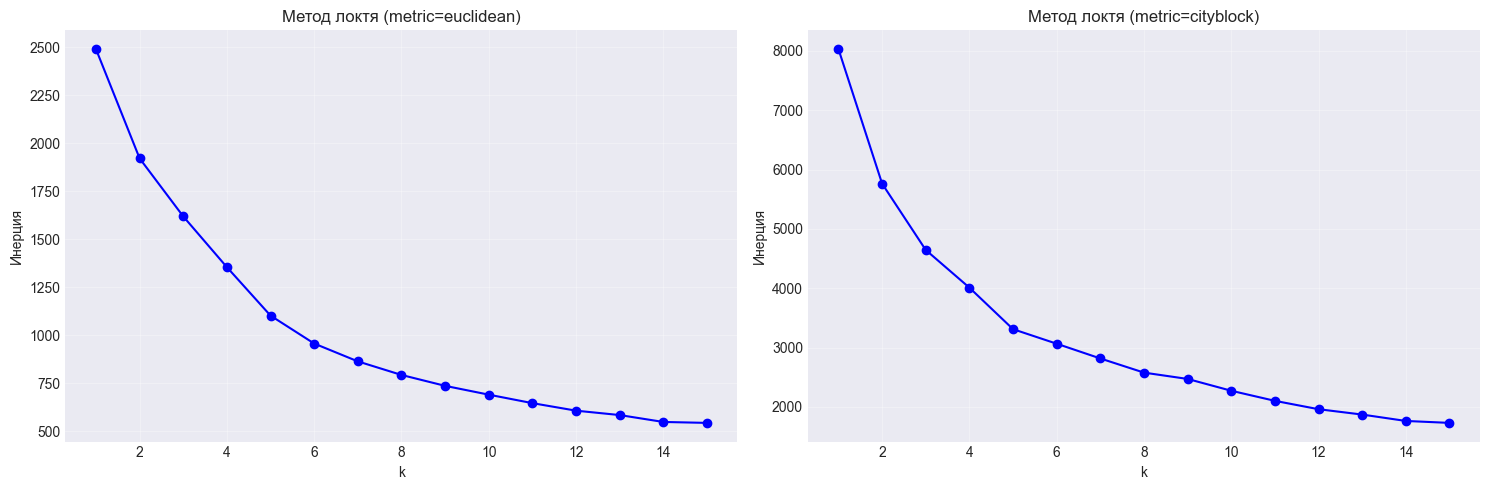

In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import pairwise_distances

def elbow_method_kmeans(X_scaled, max_k=15, metric='euclidean'):
    """Вычисление инерции для метода локтя"""
    inertias = []
    k_range = range(1, max_k + 1)

    if metric == 'euclidean':
        for k in k_range:
            kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
            kmeans.fit(X_scaled)
            inertias.append(kmeans.inertia_)
    else:
        for k in k_range:
            kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
            kmeans.fit(X_scaled)
            distances = pairwise_distances(X_scaled, kmeans.cluster_centers_, metric=metric)
            inertia = np.sum(np.min(distances, axis=1) ** 2)
            inertias.append(inertia)

    return k_range, inertias

# Анализ для разных метрик
metrics_kmeans = ['euclidean', 'cityblock']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
optimal_k_values = {}

for idx, metric in enumerate(metrics_kmeans):
    print(f"\n{'='*50}")
    print(f"k-means с метрикой: {metric}")
    print('='*50)

    k_range, inertias = elbow_method_kmeans(X_scaled, max_k=15, metric=metric)

    # Построение графика
    axes[idx].plot(k_range, inertias, 'bo-')
    axes[idx].set_title(f'Метод локтя (metric={metric})')
    axes[idx].set_xlabel('k')
    axes[idx].set_ylabel('Инерция')
    axes[idx].grid(True, alpha=0.3)

    # Нахождение точки перегиба (оптимального k)
    diffs = np.diff(inertias)
    diffs2 = np.diff(diffs)
    optimal_k = np.argmax(diffs2) + 2
    optimal_k = max(2, min(optimal_k, 10))

    optimal_k_values[metric] = optimal_k
    print(f"Оптимальное k: {optimal_k}")

plt.tight_layout()
plt.show()

Выполним кластеризацию алгоритмом k-means++  для найденного `k` с разными 
метриками. 

In [6]:
# Выполните кластеризацию алгоритмом k-means++ для найденного k с разными метриками

kmeans_results = {}

for metric in metrics_kmeans:
    print(f"\n{'='*50}")
    print(f"k-means++ с метрикой: {metric}")
    optimal_k = optimal_k_values[metric]

    # Кластеризация с найденным k
    if metric == 'euclidean':
        kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
        labels = kmeans.fit_predict(X_scaled)
    else:
        kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
        kmeans.fit(X_scaled)
        labels = kmeans.labels_

    # Оценка качества
    if len(set(labels)) > 1:
        silhouette = silhouette_score(X_scaled, labels, metric=metric)
        print(f"Коэффициент силуэта: {silhouette:.4f}")
        kmeans_results[metric] = {'k': optimal_k, 'silhouette': silhouette, 'labels': labels}
    else:
        print("Только один кластер!")

# Вывод всех результатов
print(f"\n{'-'*50}")
print("Результаты:")
for metric, result in kmeans_results.items():
    print(f"{metric}: k={result['k']}, silhouette={result['silhouette']:.4f}")


k-means++ с метрикой: euclidean
Коэффициент силуэта: 0.3281

k-means++ с метрикой: cityblock
Коэффициент силуэта: 0.3584

--------------------------------------------------
Результаты:
euclidean: k=2, silhouette=0.3281
cityblock: k=2, silhouette=0.3584


Визуализация результатов на плоскости.

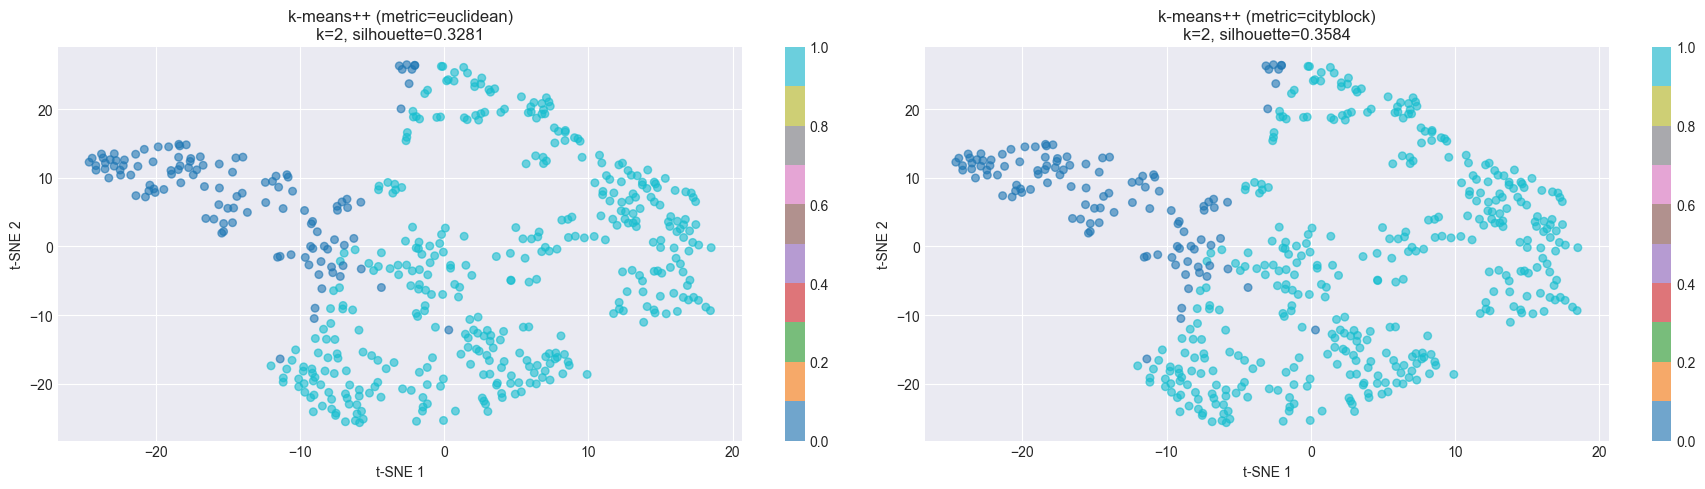

КОЭФ.Т СИЛУЭТА ДЛЯ КАЖДОГО РАЗБИЕНИЯ:
-----------------------------------
Метрика         k     Silhouette
-----------------------------------
euclidean       2     0.3281
cityblock       2     0.3584


In [7]:
# t-SNE для визуализации
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

# Визуализация результатов для каждой метрики
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

for idx, (metric, result) in enumerate(kmeans_results.items()):
    # t-SNE визуализация
    scatter = axes[idx].scatter(X_tsne[:, 0], X_tsne[:, 1],
                                c=result['labels'], cmap='tab10', alpha=0.6, s=30)
    axes[idx].set_title(f'k-means++ (metric={metric})\nk={result["k"]}, silhouette={result["silhouette"]:.4f}')
    axes[idx].set_xlabel('t-SNE 1')
    axes[idx].set_ylabel('t-SNE 2')
    plt.colorbar(scatter, ax=axes[idx])

plt.tight_layout()
plt.show()

# Дополнительно: вывод всех силуэтов в таблицу
print("КОЭФ.Т СИЛУЭТА ДЛЯ КАЖДОГО РАЗБИЕНИЯ:")
print("-"*35)
print(f"{'Метрика':<15} {'k':<5} {'Silhouette':<10}")
print("-"*35)
for metric, result in kmeans_results.items():
    print(f"{metric:<15} {result['k']:<5} {result['silhouette']:.4f}")


#### __3. Плотностной алгоритм DBSCAN__

Метрики расстояния: Евклидова, Манхэттенская. Подберем параметры `eps` (радиус окрестности) и `MinPts` (минимальное количество 
точек в окрестности) для каждой метрики расстояния, чтобы получить осмысленное разбиение. 

ПОДБОР ПАРАМЕТРОВ DBSCAN

DBSCAN с метрикой: euclidean


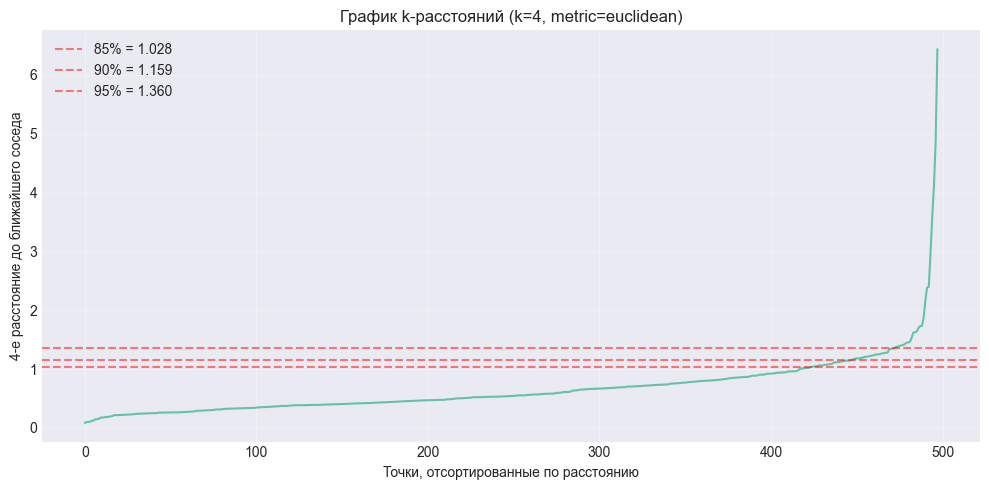

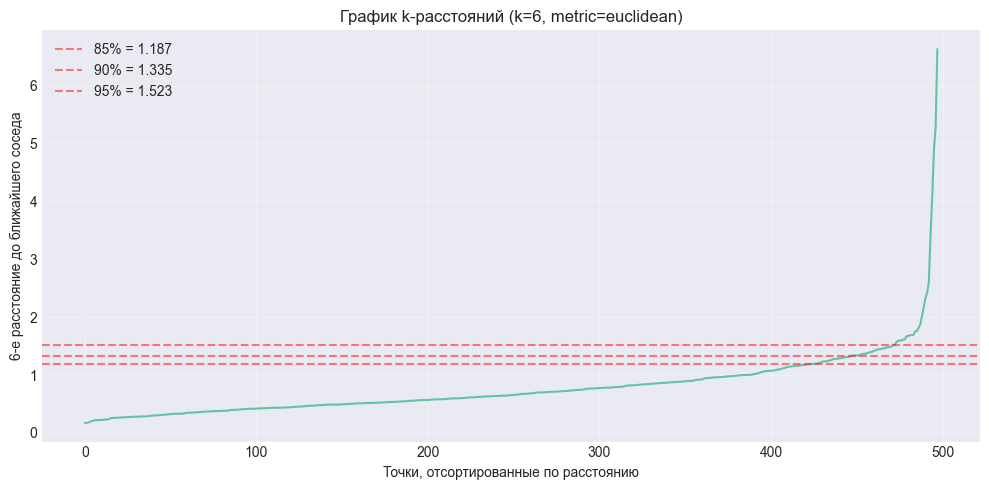

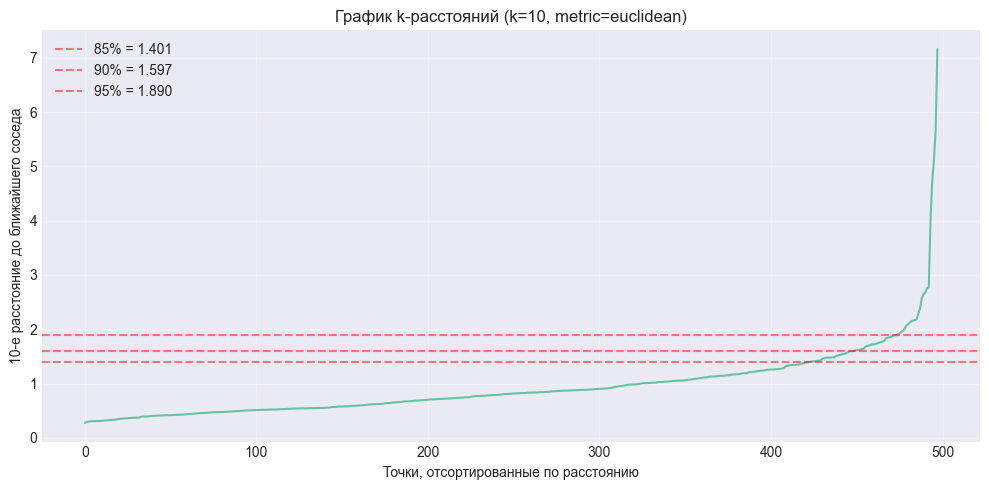


✓ Найдены оптимальные параметры:
  min_pts = 4
  eps = 1.3599 (перцентиль: 95%)
  Количество кластеров: 2
  Количество шумовых точек: 12 (2.4%)
  Коэффициент силуэта (без шума): 0.4090

DBSCAN с метрикой: cityblock


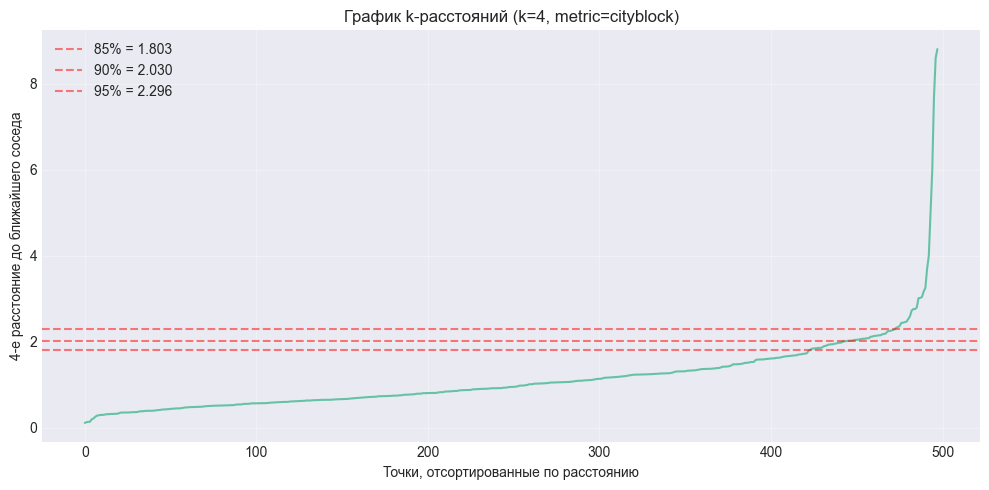

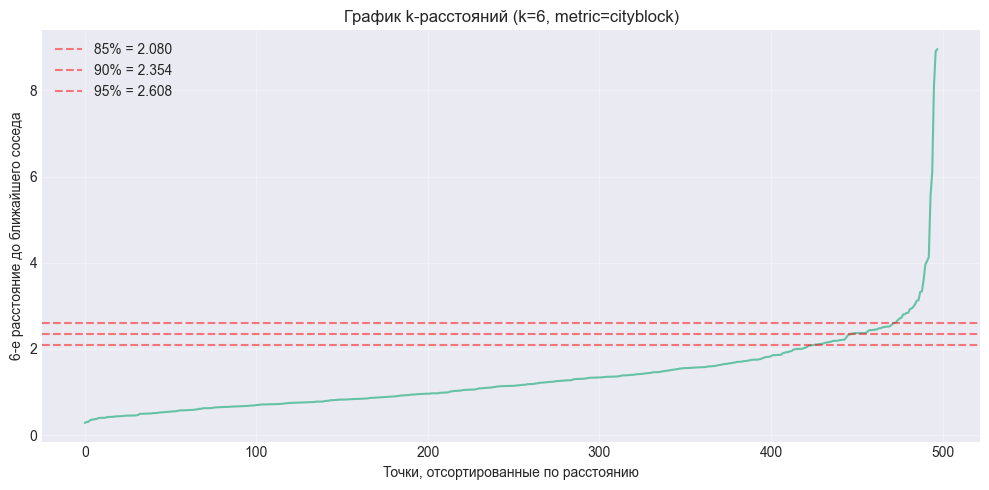

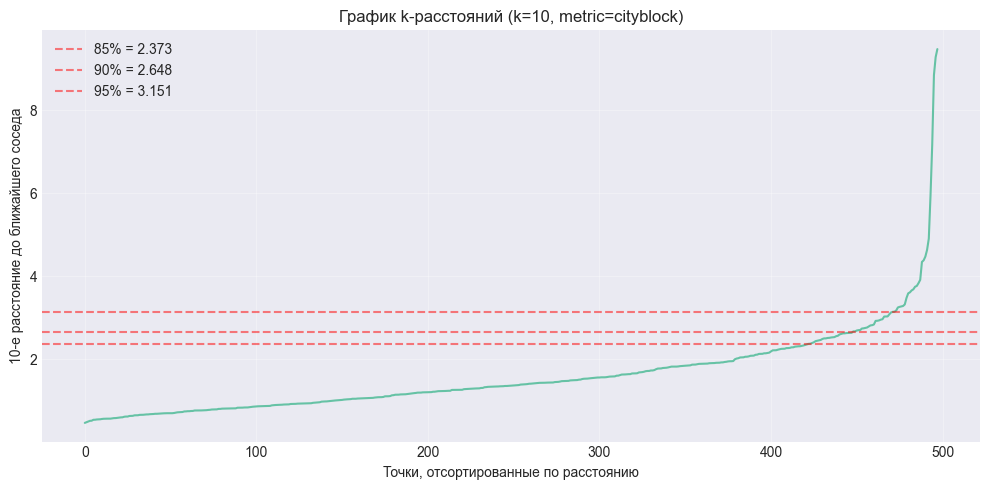


✓ Найдены оптимальные параметры:
  min_pts = 5
  eps = 2.1577 (перцентиль: 90%)
  Количество кластеров: 2
  Количество шумовых точек: 21 (4.2%)
  Коэффициент силуэта (без шума): 0.4282


In [8]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

def find_optimal_dbscan_params(X_scaled, metric='euclidean'):
    """Поиск оптимальных параметров eps и min_pts для DBSCAN"""
    best_results = []
    min_pts_range = [3, 4, 5]

    for min_pts in min_pts_range:
        if min_pts >= len(X_scaled):
            continue

        # График k-расстояний
        neigh = NearestNeighbors(n_neighbors=min_pts, metric=metric)
        neigh.fit(X_scaled)
        distances, _ = neigh.kneighbors(X_scaled)
        k_distances = np.sort(distances[:, -1])

        # Пробуем разные eps на основе квантилей
        percentiles = [50, 60, 70, 75, 80, 85, 90, 92, 95, 97, 98, 99]

        for p in percentiles:
            eps = np.percentile(k_distances, p)
            if eps < 0.01:
                continue

            dbscan = DBSCAN(eps=eps, min_samples=min_pts, metric=metric)
            labels = dbscan.fit_predict(X_scaled)

            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            n_noise = list(labels).count(-1)
            noise_ratio = n_noise / len(labels)

            if n_clusters >= 2 and n_clusters <= 15 and noise_ratio <= 0.6:
                mask = labels != -1
                if mask.sum() > 10 and len(set(labels[mask])) >= 2:
                    try:
                        silhouette = silhouette_score(X_scaled[mask], labels[mask], metric=metric)
                        best_results.append({
                            'min_pts': min_pts,
                            'eps': eps,
                            'n_clusters': n_clusters,
                            'n_noise': n_noise,
                            'noise_ratio': noise_ratio,
                            'silhouette': silhouette,
                            'labels': labels,
                            'percentile': p
                        })
                    except Exception:
                        pass

    if best_results:
        best_results.sort(key=lambda x: x['silhouette'], reverse=True)
        return best_results[0]
    return None

def plot_k_distance_graph(X_scaled, metric='euclidean', min_pts=4):
    """Построение графика k-расстояний"""
    neigh = NearestNeighbors(n_neighbors=min_pts, metric=metric)
    neigh.fit(X_scaled)
    distances, _ = neigh.kneighbors(X_scaled)
    k_distances = np.sort(distances[:, -1])

    plt.figure(figsize=(10, 5))
    plt.plot(k_distances)
    plt.title(f'График k-расстояний (k={min_pts}, metric={metric})')
    plt.xlabel('Точки, отсортированные по расстоянию')
    plt.ylabel(f'{min_pts}-е расстояние до ближайшего соседа')
    plt.grid(True, alpha=0.3)

    for percentile in [85, 90, 95]:
        eps_val = np.percentile(k_distances, percentile)
        plt.axhline(y=eps_val, color='r', linestyle='--', alpha=0.5,
                   label=f'{percentile}% = {eps_val:.3f}')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return k_distances

metrics_dbscan = ['euclidean', 'cityblock']
dbscan_results = {}

print("="*60)
print("ПОДБОР ПАРАМЕТРОВ DBSCAN")
print("="*60)

for metric in metrics_dbscan:
    print(f"\n{'='*50}")
    print(f"DBSCAN с метрикой: {metric}")
    print('='*50)

    # Графики k-расстояний для разных k
    for k in [4, 6, 10]:
        plot_k_distance_graph(X_scaled, metric=metric, min_pts=k)

    # Поиск оптимальных параметров
    best = find_optimal_dbscan_params(X_scaled, metric=metric)

    if best:
        print(f"\n✓ Найдены оптимальные параметры:")
        print(f"  min_pts = {best['min_pts']}")
        print(f"  eps = {best['eps']:.4f} (перцентиль: {best['percentile']}%)")
        print(f"  Количество кластеров: {best['n_clusters']}")
        print(f"  Количество шумовых точек: {best['n_noise']} ({best['noise_ratio']:.1%})")
        print(f"  Коэффициент силуэта (без шума): {best['silhouette']:.4f}")
        dbscan_results[metric] = best
    else:
        print(f"\n✗ Не удалось найти подходящие параметры для метрики {metric}")

Визуализация результатов DBSCAN

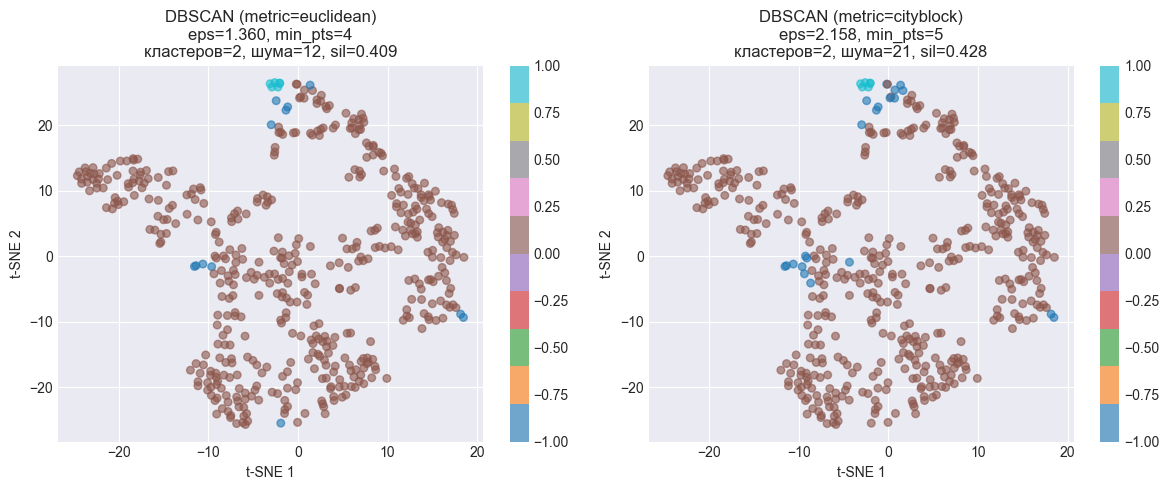

In [9]:
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

# Визуализация результатов DBSCAN для каждой метрики
if dbscan_results:
    fig, axes = plt.subplots(1, len(dbscan_results), figsize=(6*len(dbscan_results), 5))
    if len(dbscan_results) == 1:
        axes = [axes]

    for idx, (metric, result) in enumerate(dbscan_results.items()):
        labels = result['labels']
        n_clusters = result['n_clusters']
        n_noise = result['n_noise']
        # Шумовые точки (метка -1) выделяем другим цветом и маркером
        scatter = axes[idx].scatter(X_tsne[:, 0], X_tsne[:, 1],
                                    c=labels, cmap='tab10', alpha=0.6, s=30)
        axes[idx].set_title(f'DBSCAN (metric={metric})\neps={result["eps"]:.3f}, min_pts={result["min_pts"]}\n'
                           f'кластеров={n_clusters}, шума={n_noise}, sil={result["silhouette"]:.3f}')
        axes[idx].set_xlabel('t-SNE 1')
        axes[idx].set_ylabel('t-SNE 2')
        plt.colorbar(scatter, ax=axes[idx])
    plt.tight_layout()
    plt.show()



Рассчет коэффициента силуэта


In [10]:
for metric, result in dbscan_results.items():
    labels = result['labels']

    # Исключаем шумовые точки (метка -1)
    mask = labels != -1
    X_filtered = X_scaled[mask]
    labels_filtered = labels[mask]

    n_clusters = len(set(labels_filtered))
    n_noise = (~mask).sum()

    print(f"\n{metric}:")
    print(f"  Всего точек: {len(labels)}")
    print(f"  Точек в кластерах: {len(X_filtered)}")
    print(f"  Количество кластеров: {n_clusters}")



euclidean:
  Всего точек: 498
  Точек в кластерах: 486
  Количество кластеров: 2

cityblock:
  Всего точек: 498
  Точек в кластерах: 477
  Количество кластеров: 2


#### __4. Сравнение результатов__

In [11]:
import pandas as pd

# Сбор данных для сводной таблицы
comparison_data = []

print("\n" + "-"*80)
print("Результаты иерархической кластеризации")
for config, result in results_hierarchical.items():
    linkage_method, metric = config.split('_')
    comparison_data.append({
        'Алгоритм': 'Иерархическая',
        'Метрика': metric,
        'Метод связи': linkage_method,
        'k (кластеры)': result['best_k'],
        'Шум (DBSCAN)': '-',
        'Silhouette': result['silhouette'],
        #'Визуальная оценка': 'Хорошо разделимые кластеры' if result['silhouette'] > 0.5 else 'Среднее разделение'
    })
    print(f"Иерархическая: {linkage_method}+{metric} → k={result['best_k']}, sil={result['silhouette']:.4f}")

# 2. K-means++ (kmeans_results)
print("\n" + "-"*80)
print("Результаты K-MEANS++")
for metric, result in kmeans_results.items():
    comparison_data.append({
        'Алгоритм': 'K-means++',
        'Метрика': metric,
        'Метод связи': '-',
        'k (кластеры)': result['k'],
        'Шум (DBSCAN)': '-',
        'Silhouette': result['silhouette'],
        #'Визуальная оценка': 'Хорошо разделимые кластеры' if result['silhouette'] > 0.5 else 'Среднее разделение'
    })
    print(f"K-means++: {metric} → k={result['k']}, sil={result['silhouette']:.4f}")

# 3. DBSCAN (dbscan_results)
print("\n" + "-"*80)
print("Результаты DBSCAN")

for metric, result in dbscan_results.items():
    comparison_data.append({
        'Алгоритм': 'DBSCAN',
        'Метрика': metric,
        'Метод связи': '-',
        'k (кластеры)': f"{result['n_clusters']} (+{result['n_noise']} шума)",
        'Шум (DBSCAN)': result['n_noise'],
        'Silhouette': result['silhouette'],
        #'Визуальная оценка': f" шум {result['noise_ratio']:.1%}"
    })
    print(f"DBSCAN: {metric} → кластеров={result['n_clusters']}, шума={result['n_noise']}, sil={result['silhouette']:.4f}")

# Создание сводной таблицы
df_comparison = pd.DataFrame(comparison_data)

# Сортировка по силуэту (от лучшего к худшему)
df_comparison = df_comparison.sort_values('Silhouette', ascending=False)

# Вывод таблицы
print("\n" + "-"*80)
print("СВОДНАЯ ТАБЛИЦА СРАВНЕНИЯ АЛГОРИТМОВ")
print(df_comparison.to_string(index=False))



--------------------------------------------------------------------------------
Результаты иерархической кластеризации
Иерархическая: single+euclidean → k=2, sil=0.6642
Иерархическая: single+cityblock → k=2, sil=0.6257
Иерархическая: single+chebyshev → k=2, sil=0.7625
Иерархическая: complete+euclidean → k=6, sil=0.3053
Иерархическая: complete+cityblock → k=3, sil=0.3916
Иерархическая: complete+chebyshev → k=6, sil=0.1527

--------------------------------------------------------------------------------
Результаты K-MEANS++
K-means++: euclidean → k=2, sil=0.3281
K-means++: cityblock → k=2, sil=0.3584

--------------------------------------------------------------------------------
Результаты DBSCAN
DBSCAN: euclidean → кластеров=2, шума=12, sil=0.4090
DBSCAN: cityblock → кластеров=2, шума=21, sil=0.4282

--------------------------------------------------------------------------------
СВОДНАЯ ТАБЛИЦА СРАВНЕНИЯ АЛГОРИТМОВ
     Алгоритм   Метрика Метод связи k (кластеры) Шум (DBSCAN)  Silh

#### __Вариант А. Мягкая (нечеткая) кластеризация__

Подготовка алгоритма Fuzzy C-Means (FCM) .

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings('ignore')

# Загрузка данных
df = pd.read_csv('Data\Dataset_3laba.csv')
features = ['memory_variability', 'max_cpus', 'max_memory', 'page_cache_memory', 'cycles_per_instruction_norm']
# Подготовка данных
X = df[features].copy()
X = X.dropna()
# Стандартизация данных
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(f"Размер данных: {X_scaled.shape[0]} наблюдений, {X_scaled.shape[1]} признаков")
print(f"Признаки: {', '.join(features)}\n")

#реализация Fuzzy C-Means
class FuzzyCMeans:

    def __init__(self, n_clusters=3, m=2.0, max_iter=150, epsilon=0.005, random_state=42):
        self.n_clusters = n_clusters
        self.m = m
        self.max_iter = max_iter
        self.epsilon = epsilon
        self.random_state = random_state
        np.random.seed(random_state)

    def _initialize_membership(self, n_samples):
        """Инициализация матрицы принадлежности"""
        u = np.random.rand(n_samples, self.n_clusters)
        u = u / u.sum(axis=1, keepdims=True)
        return u

    def _update_centers(self, X, u):
        """Обновление центров кластеров"""
        um = u ** self.m
        centers = np.dot(um.T, X) / um.sum(axis=0)[:, np.newaxis]
        return centers

    def _update_membership(self, X, centers):
        """Обновление матрицы принадлежности"""
        n_samples = X.shape[0]
        u = np.zeros((n_samples, self.n_clusters))
        for i in range(n_samples):
            distances = np.linalg.norm(X[i] - centers, axis=1)
            zero_dist_mask = distances == 0
            if np.any(zero_dist_mask):
                u[i, zero_dist_mask] = 1.0
                u[i, ~zero_dist_mask] = 0.0
            else:
                power = 2.0 / (self.m - 1)
                for j in range(self.n_clusters):
                    denominator = np.sum((distances[j] / (distances + 1e-10)) ** power)
                    u[i, j] = 1.0 / (denominator + 1e-10)

        u = u / u.sum(axis=1, keepdims=True)
        return u

    def fit(self, X):
        """Обучение модели FCM"""
        n_samples = X.shape[0]
        self.u = self._initialize_membership(n_samples)
        for iteration in range(self.max_iter):
            u_old = self.u.copy()
            self.centers = self._update_centers(X, self.u)
            self.u = self._update_membership(X, self.centers)
            if np.linalg.norm(self.u - u_old) < self.epsilon:
                print(f"    Сходимость достигнута на итерации {iteration + 1}")
                break
        return self
    def predict(self, X):
        """Предсказание жестких меток"""
        if not hasattr(self, 'centers'):
            raise ValueError("Модель не обучена")
        u = self._update_membership(X, self.centers)
        return np.argmax(u, axis=1)



Размер данных: 498 наблюдений, 5 признаков
Признаки: memory_variability, max_cpus, max_memory, page_cache_memory, cycles_per_instruction_norm



Выполним кластеризацию с разными значениями параметра нечеткости `m` и разными метриками расстояния 

In [13]:
# 1. Жесткая кластеризация (K-Means) для сравнения
print("1. Жесткая кластеризация (K-Means)")
print("-" * 40)
n_clusters = 3
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
kmeans_centers = kmeans.cluster_centers_

print(f"Количество кластеров: {n_clusters}")
print(f"Распределение точек по кластерам:")
for i in range(n_clusters):
    count = np.sum(kmeans_labels == i)
    print(f"  Кластер {i}: {count} точек ({count/len(kmeans_labels)*100:.1f}%)")

# 2. Мягкая кластеризация (Fuzzy C-Means) с разными параметрами
print("\n2. Мягкая кластеризация (Fuzzy C-Means")
print("-" * 40)
def run_fcm(X_scaled, n_clusters, m, max_iter=150, epsilon=0.005):
    """Запуск FCM с заданными параметрами"""
    fcm = FuzzyCMeans(n_clusters=n_clusters, m=m, max_iter=max_iter, epsilon=epsilon)
    fcm.fit(X_scaled)
    return fcm

# Параметры для экспериментов
m_values = [1.5, 2.0, 2.5,3.0]
#m_values = [1.1, 1.8, 2.0,2.5]
fcm_results = {}

for m in m_values:
    print(f"\nЗапуск FCM с m = {m}")
    fcm = run_fcm(X_scaled, n_clusters, m)
    fcm_results[m] = fcm

    hard_labels = np.argmax(fcm.u, axis=1)

    print(f"  Распределение точек по кластерам:")
    for i in range(n_clusters):
        count = np.sum(hard_labels == i)
        print(f"    Кластер {i}: {count} точек ({count/len(hard_labels)*100:.1f}%)")

    entropy = -np.sum(fcm.u * np.log(fcm.u + 1e-10), axis=1).mean()
    print(f"  Средняя энтропия принадлежности: {entropy:.4f}")

print("\n3. ВЫБОР 5 ТОЧЕК ДЛЯ АНАЛИЗА ПРИНАДЛЕЖНОСТИ")
print("-" * 40)

selected_indices = [287, 299, 306, 234, 245, 235]
selected_types = ['','','','','','']

print(f"Выбрано {len(selected_indices)} точек для анализа:")
for i, (idx, typ) in enumerate(zip(selected_indices, selected_types)):
    print(f"  {i+1}. {typ} (индекс {idx})")

1. Жесткая кластеризация (K-Means)
----------------------------------------
Количество кластеров: 3
Распределение точек по кластерам:
  Кластер 0: 91 точек (18.3%)
  Кластер 1: 345 точек (69.3%)
  Кластер 2: 62 точек (12.4%)

2. Мягкая кластеризация (Fuzzy C-Means
----------------------------------------

Запуск FCM с m = 1.5
    Сходимость достигнута на итерации 21
  Распределение точек по кластерам:
    Кластер 0: 94 точек (18.9%)
    Кластер 1: 198 точек (39.8%)
    Кластер 2: 206 точек (41.4%)
  Средняя энтропия принадлежности: 0.5222

Запуск FCM с m = 2.0
    Сходимость достигнута на итерации 35
  Распределение точек по кластерам:
    Кластер 0: 196 точек (39.4%)
    Кластер 1: 100 точек (20.1%)
    Кластер 2: 202 точек (40.6%)
  Средняя энтропия принадлежности: 0.8770

Запуск FCM с m = 2.5
    Сходимость достигнута на итерации 79
  Распределение точек по кластерам:
    Кластер 0: 159 точек (31.9%)
    Кластер 1: 131 точек (26.3%)
    Кластер 2: 208 точек (41.8%)
  Средняя энтропи

Визуализация векторов вероятностей для точек

Визуализация векторов вероятностей для точек


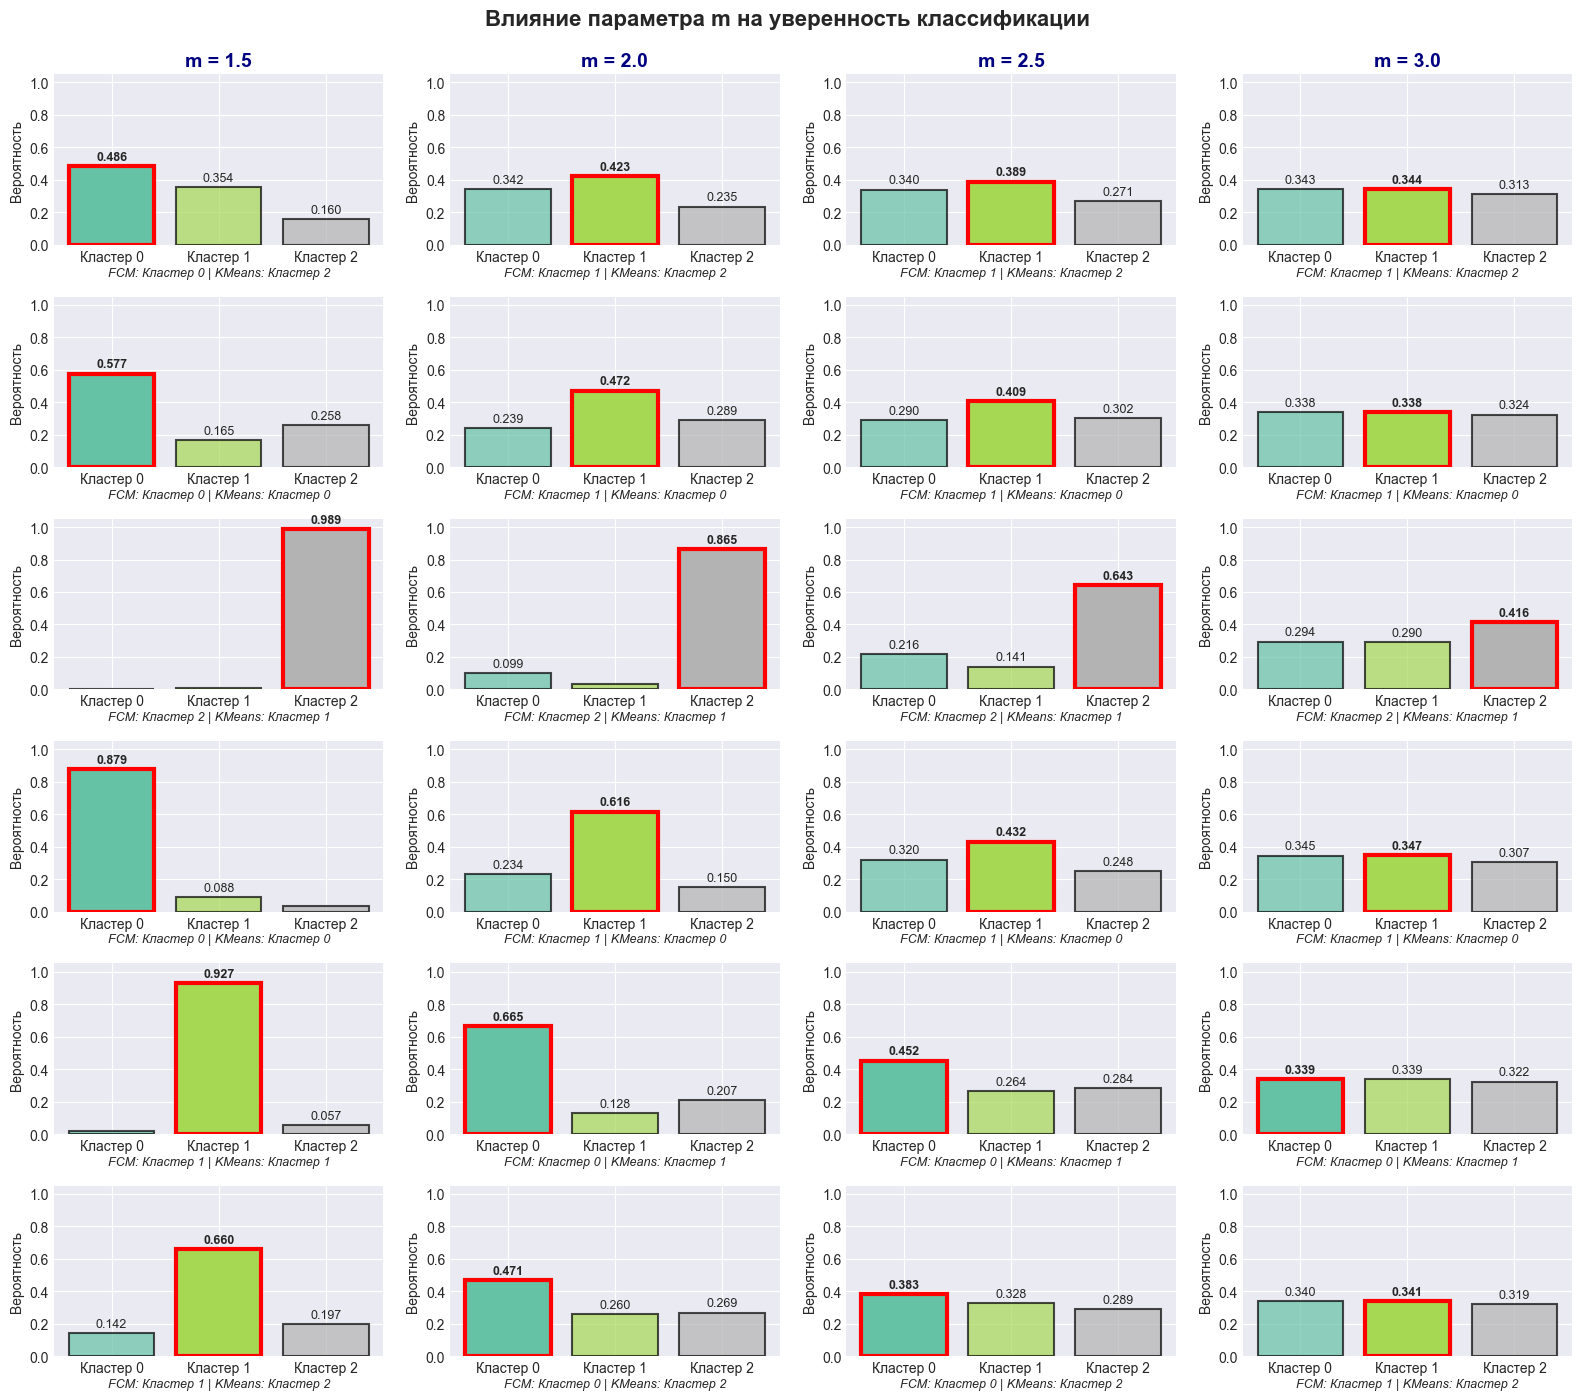

In [14]:
print("Визуализация векторов вероятностей для точек")
def plot_membership_vectors_6points(selected_indices, selected_types, fcm_results, kmeans_labels):

    n_points = len(selected_indices)
    n_m = len(fcm_results)
    n_clusters = list(fcm_results.values())[0].u.shape[1]

    fig, axes = plt.subplots(n_points, n_m, figsize=(16, 14))
    if n_points == 1:
        axes = axes.reshape(1, -1)

    colors = plt.cm.Set2(np.linspace(0, 1, n_clusters))

    for i, (idx, typ) in enumerate(zip(selected_indices, selected_types)):
        for j, (m, fcm) in enumerate(fcm_results.items()):
            ax = axes[i, j]

            # Вероятности принадлежности
            probs = fcm.u[idx]
            hard_label = np.argmax(probs)
            kmeans_label = kmeans_labels[idx]

            # Столбчатая диаграмма
            bars = ax.bar(range(n_clusters), probs, color=colors, alpha=0.7, edgecolor='black', linewidth=1.5)

            # Выделяем максимальную вероятность
            bars[hard_label].set_alpha(1.0)
            bars[hard_label].set_edgecolor('red')
            bars[hard_label].set_linewidth(3)

            ax.set_ylim(0, 1.05)
            ax.set_xticks(range(n_clusters))
            ax.set_xticklabels([f'Кластер {k}' for k in range(n_clusters)], fontsize=10)
            ax.set_ylabel('Вероятность', fontsize=10)

            if i == 0:
                ax.set_title(f'm = {m}', fontsize=14, fontweight='bold', color='navy')

            if j == 0:
                # Красивое оформление названия точки
                # Для точки 21 используем особое выделение
                if ' ' in typ:
                    box_color = 'lightgreen'
                else:
                    box_color = 'lightblue'

                ax.text(-0.35, 0.5, typ.replace(': ', '\n'),
                       transform=ax.transAxes, fontsize=10,
                       verticalalignment='center', horizontalalignment='right',
                       bbox=dict(boxstyle='round', facecolor=box_color, alpha=0.7),
                       fontweight='bold')

            # Информация о метках
            ax.text(0.5, -0.18, f'FCM: Кластер {hard_label} | KMeans: Кластер {kmeans_label}',
                   transform=ax.transAxes, fontsize=9, ha='center', style='italic')

            # Значения вероятностей над столбцами
            for bar, prob in zip(bars, probs):
                if prob > 0.05:
                    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.02,
                           f'{prob:.3f}', ha='center', va='bottom', fontsize=9,
                           fontweight='bold' if prob == max(probs) else 'normal')

    plt.suptitle('Влияние параметра m на уверенность классификации',
                 fontsize=16, fontweight='bold', y=0.995)
    plt.tight_layout()

# Построение графиков
plot_membership_vectors_6points(selected_indices, selected_types, fcm_results, kmeans_labels)

In [15]:
print("Сравнение жестких меток K-Means и FCM")
print("-" * 40)
for m, fcm in fcm_results.items():
    fcm_hard = np.argmax(fcm.u, axis=1)
    agreement = np.mean(fcm_hard == kmeans_labels)
    print(f"m = {m}: согласие с K-Means = {agreement:.2%}")

Сравнение жестких меток K-Means и FCM
----------------------------------------
m = 1.5: согласие с K-Means = 61.24%
m = 2.0: согласие с K-Means = 9.44%
m = 2.5: согласие с K-Means = 12.65%
m = 3.0: согласие с K-Means = 26.51%


Влияние $m$ на энтропию (размытость)
Алгоритм относит точки к кластерам уверенно только при низких значениях $m$ . Увеличение параметра m ведет к  росту неопределенности.
- При $m = 1.5$ энтропия минимальна — это значит, что алгоритм четко понимает, какую точку в какой кластер отправить.

С ростом $m$ алгоритм перестает учитывать расстояния до центров.